# 00. Исследовательский анализ данных (EDA)

**Дипломный проект:** выявление банковских рисков по текстам русскоязычных новостей.

На этом этапе анализируем структуру и качество **неизменённого исходного датасета** перед обучением моделей. Изучаем баланс классов, распределения по банкам, источникам и времени, характеристики текстов, согласованность разметки, структуру фиксированных выборок и возможные совпадения новостей между ними.

**Задачи исследования:**
- **Бинарная классификация:** `alert_flag` (`0` — нет риска, `1` — есть риск).
- **Дополнительная многоклассовая классификация:** `risk_type_4cls` (4 класса).

EDA — описательный анализ: он **не обучает модели, не подбирает гиперпараметры и не меняет исходный CSV**. Результаты обучения и сравнение baseline с mDeBERTa представлены в `03_binary_experiments_comparison.ipynb`.


## 1. Загрузка и проверка датасета

Исходный CSV расположен в `data/bank_risk_dataset.csv`. Контрольная сумма сверяется с результатами экспериментов. Рабочим каталогом служит корень проекта.

In [2]:
from pathlib import Path
import re
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option('display.max_colwidth', 110)
plt.rcParams['figure.figsize'] = (9, 4)

# Датасет находится внутри распакованного проекта, в папке data/.
# VS Code может запускать ячейки из рабочей папки, отличной от папки ноутбука.
# Ищем проект рядом с текущей рабочей папкой или выше, не требуя Google Colab.
def find_data_dir():
    current = Path.cwd().resolve()
    locations = [current, *list(current.parents)[:4]]
    for folder in locations:
        if (folder / 'data' / 'bank_risk_dataset.csv').is_file():
            return folder / 'data'
    # Если рабочая папка VS Code — родительская для распакованного архива.
    matches = sorted(current.glob('bank_risk_diploma_results*/data/bank_risk_dataset.csv'))
    if len(matches) == 1:
        return matches[0].parent
    raise FileNotFoundError(
        f'Не найден data/bank_risk_dataset.csv. Текущая папка: {current}. '
        'Рабочий каталог должен содержать data/bank_risk_dataset.csv. '
        ''
    )

DATA_DIR = find_data_dir()
PROJECT_ROOT = DATA_DIR.parent
DATA_PATH = DATA_DIR / 'bank_risk_dataset.csv'
print('Корень проекта:', PROJECT_ROOT)

EXPECTED_SHA256 = '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3'
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, (
    f'Контрольная сумма отличается: {actual_sha256}. '
    'Требуется исходный датасет с зафиксированной контрольной суммой.'
)

df = pd.read_csv(DATA_PATH, keep_default_na=False)
required = {
    'sample_id', 'event_group_id', 'split', 'text_fragment', 'title',
    'entity_norm', 'found_risk_keywords', 'source', 'published_year',
    'published_month', 'alert_flag', 'risk_type_4cls'
}
assert required.issubset(df.columns), f'Отсутствуют столбцы: {required - set(df.columns)}'
assert set(df['alert_flag'].unique()) == {0, 1}, 'Ожидаются бинарные метки 0 и 1.'
assert set(df['split'].unique()) == {'train', 'valid', 'test'}, 'Ожидаются значения split: train, valid, test.'

print('Датасет:', DATA_PATH)
print(f'Строк: {len(df):,}; столбцов: {len(df.columns)}')
print('SHA256 проверена — исходный датасет совпадает с экспериментами.')
display(df[['title', 'entity_norm', 'alert_flag', 'risk_type_4cls', 'split']].head())


Корень проекта: D:\bank_risk_diploma_final_multiclass_2026_10_25\_review_execution
Датасет: D:\bank_risk_diploma_final_multiclass_2026_10_25\_review_execution\data\bank_risk_dataset.csv
Строк: 5,041; столбцов: 12
SHA256 проверена — исходный датасет совпадает с экспериментами.


,title,entity_norm,alert_flag,risk_type_4cls,split
0,"Газпромбанк и РСХБ самоустранились от проекта ""Едим дома!""",Росбанк,0,no_risk,train
1,Хакеры четыре года грабили клиентов Сбербанка и ВТБ,ВТБ,1,cyber_risk,train
2,"Exxon и ""Роснефть"" прекратили бурение в Арктике из-за санкций",Газпромбанк,0,no_risk,train
3,Российские банки захотели оценивать расходы клиентов по картам при выдаче кредитов,ВТБ,0,no_risk,train
4,«Открытие» и «Росгосстрах» создадут крупнейшую частную финансовую группу,Банк Открытие,0,no_risk,train


## 2. Структура и полнота данных

Каждая строка — фрагмент новости, связанный с определённым банком. Одна новость может присутствовать в нескольких строках, если относится к разным банкам. Это важно при поиске дубликатов.

In [3]:
column_summary = pd.DataFrame({
    'Поле': df.columns,
    'Тип': [str(df[col].dtype) for col in df.columns],
    'Пустых значений': [
        int(df[col].isna().sum() + df[col].astype(str).str.strip().eq('').sum())
        for col in df.columns
    ],
    'Уникальных значений': [df[col].nunique(dropna=False) for col in df.columns]
})
display(column_summary)

print('Повторяющихся sample_id:', int(df['sample_id'].duplicated().sum()))
print('Пустых текстов:', int(df['text_fragment'].astype(str).str.strip().eq('').sum()))
print('Банков:', df['entity_norm'].nunique())
print('Источников:', df['source'].nunique())

,Поле,Тип,Пустых значений,Уникальных значений
0,sample_id,object,0,5041
1,event_group_id,object,0,4970
2,split,object,0,3
3,text_fragment,object,0,4980
4,title,object,1,4584
5,entity_norm,object,0,15
6,found_risk_keywords,object,4305,77
7,source,object,0,5
8,published_year,int64,0,22
9,published_month,int64,0,12


Повторяющихся sample_id: 0
Пустых текстов: 0
Банков: 15
Источников: 5


## 3. Распределение классов

Нас интересует бинарная метка `alert_flag`: **0** — риск не отмечен, **1** — есть риск-сигнал. Если положительных примеров мало, высокая Accuracy не означает, что модель научилась находить риски. Поэтому в последующих ноутбуках основной метрикой будет F1.

,Класс,Количество,"Доля, %"
0,Нет риска (0),4787,94.96
1,Есть риск (1),254,5.04


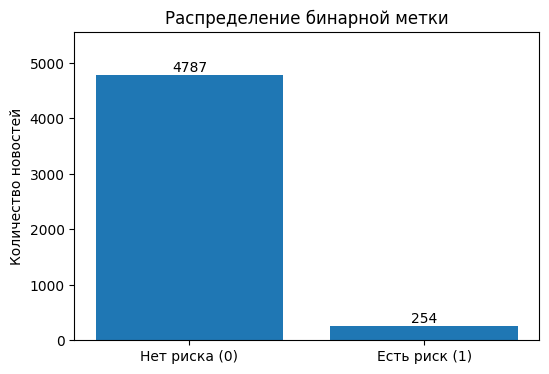

Доля положительного класса: 5.04%


In [4]:
class_counts = df['alert_flag'].value_counts().reindex([0, 1], fill_value=0)
class_table = pd.DataFrame({
    'Класс': ['Нет риска (0)', 'Есть риск (1)'],
    'Количество': class_counts.to_numpy(),
    'Доля, %': (100 * class_counts / len(df)).round(2).to_numpy()
})
display(class_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_table['Класс'], class_table['Количество'])
ax.set_title('Распределение бинарной метки')
ax.set_ylabel('Количество новостей')
for i, value in enumerate(class_table['Количество']):
    ax.text(i, value + len(df) * 0.012, str(value), ha='center')
ax.set_ylim(0, class_table['Количество'].max() * 1.16)
plt.show()

print(f'Доля положительного класса: {df.alert_flag.mean():.2%}')

## 4. Типы банковских рисков

Поле `risk_type_4cls` понадобится для изучения структуры датасета и ошибок модели. Само по себе оно не должно попадать в признаки бинарного классификатора: это ещё одна форма целевой разметки.

,Тип риска,Количество,"Доля, %"
0,no_risk,4787,94.96
1,cyber_risk,111,2.20
2,operational_risk,97,1.92
3,regulatory_risk,46,0.91


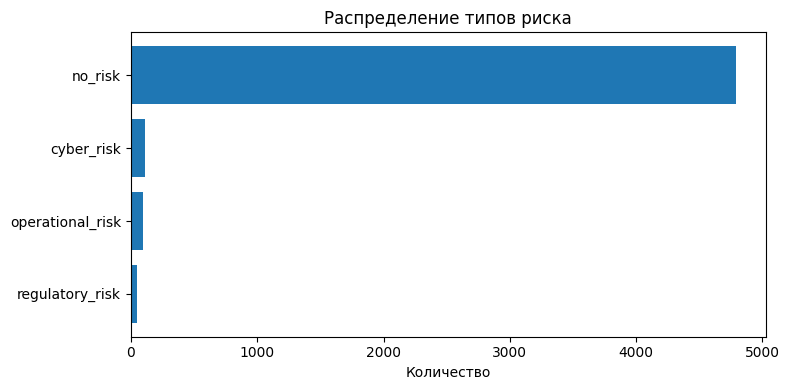

Несоответствий alert_flag и risk_type_4cls: 0


In [5]:
risk_table = df['risk_type_4cls'].value_counts().rename_axis('Тип риска').reset_index(name='Количество')
risk_table['Доля, %'] = (100 * risk_table['Количество'] / len(df)).round(2)
display(risk_table)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(risk_table['Тип риска'][::-1], risk_table['Количество'][::-1])
ax.set(xlabel='Количество', title='Распределение типов риска')
plt.tight_layout()
plt.show()

contradictions = (
    ((df['alert_flag'] == 0) & (df['risk_type_4cls'] != 'no_risk')) |
    ((df['alert_flag'] == 1) & (df['risk_type_4cls'] == 'no_risk'))
)
print('Несоответствий alert_flag и risk_type_4cls:', int(contradictions.sum()))

## 5. Разбиение на train, validation и test

Используем готовую колонку `split`. Переразбивать датасет не нужно: обе модели должны обучаться и оцениваться на **одних и тех же** выборках. Проверим количество примеров и долю риска.

,Нет риска,Есть риск,Всего,"Доля риска, %"
split,,,,
train,3359,176,3535,4.98
valid,715,40,755,5.30
test,713,38,751,5.06


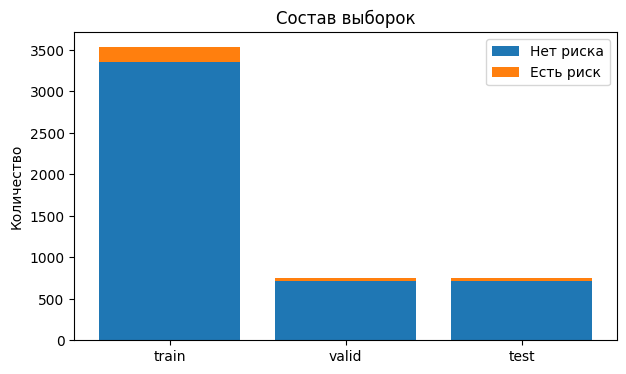

In [6]:
split_table = pd.crosstab(df['split'], df['alert_flag']).reindex(['train', 'valid', 'test'])
split_table.columns = ['Нет риска', 'Есть риск']
split_table['Всего'] = split_table.sum(axis=1)
split_table['Доля риска, %'] = (100 * split_table['Есть риск'] / split_table['Всего']).round(2)
display(split_table)

fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(len(split_table))
ax.bar(xs, split_table['Нет риска'], label='Нет риска')
ax.bar(xs, split_table['Есть риск'], bottom=split_table['Нет риска'], label='Есть риск')
ax.set(xticks=xs, xticklabels=split_table.index, ylabel='Количество', title='Состав выборок')
ax.legend()
plt.show()

## 6. Банки

Сравним количество записей и долю положительных примеров для каждого банка. **Доля риска в этом наборе — не реальная частота рисков в банке**: она зависит от того, как собирались и размечались новости.

,Количество,Риск,"Доля риска, %"
entity_norm,,,
ВТБ,2044,53,2.59
Сбербанк,1731,130,7.51
Газпромбанк,275,6,2.18
Альфа-Банк,262,21,8.02
Промсвязьбанк,144,5,3.47
Россельхозбанк,132,12,9.09
Т-Банк,104,9,8.65
Банк Открытие,94,3,3.19
Райффайзенбанк,92,7,7.61


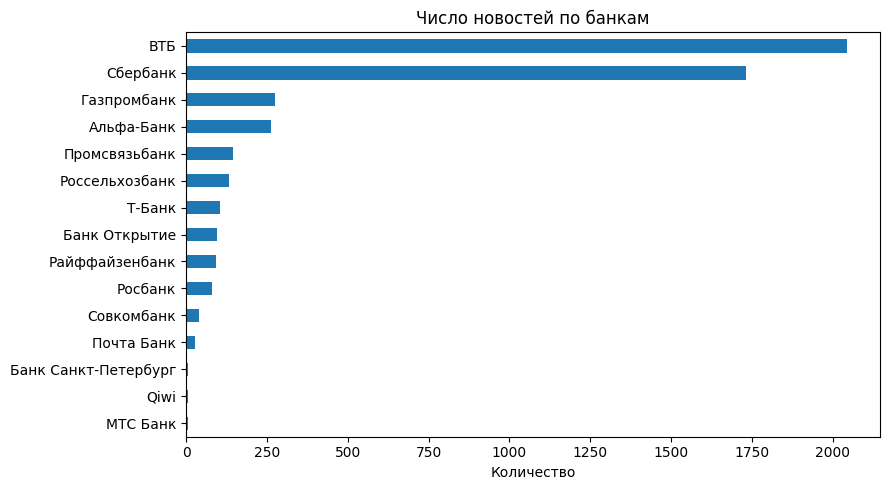

In [7]:
banks = (df.groupby('entity_norm')['alert_flag']
           .agg(Количество='size', Риск='sum', Доля_риска='mean')
           .sort_values('Количество', ascending=False))
banks['Доля риска, %'] = (100 * banks.pop('Доля_риска')).round(2)
display(banks)

fig, ax = plt.subplots(figsize=(9, 5))
banks['Количество'].sort_values().plot.barh(ax=ax)
ax.set(xlabel='Количество', ylabel='', title='Число новостей по банкам')
plt.tight_layout()
plt.show()

## 7. Источники публикаций

Источники различаются по тематике и стилю. Если доля положительных новостей сильно зависит от источника, модель может частично опираться на особенности текста конкретного издания.

,Количество,Риск,"Доля риска, %"
source,,,
buriy,1590,74,4.65
ods_tass,1450,54,3.72
lenta,1017,48,4.72
telegram_contest,584,40,6.85
taiga_fontanka,400,38,9.50


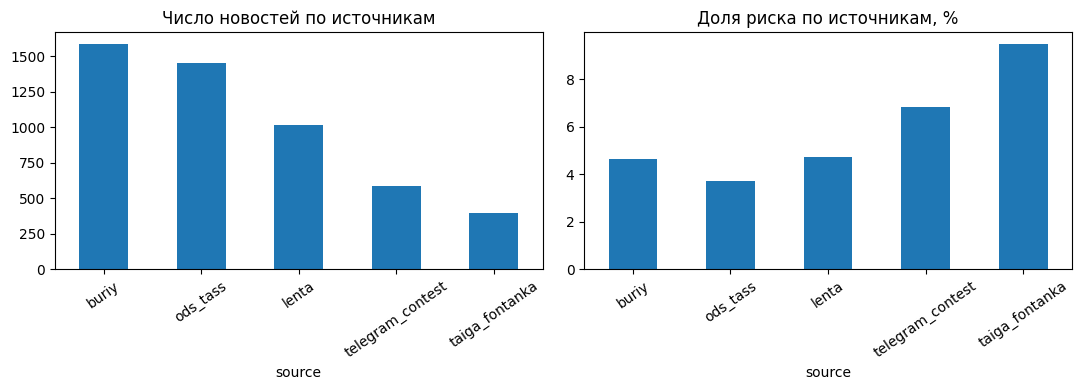

In [8]:
sources = (df.groupby('source')['alert_flag']
           .agg(Количество='size', Риск='sum', Доля_риска='mean')
           .sort_values('Количество', ascending=False))
sources['Доля риска, %'] = (100 * sources.pop('Доля_риска')).round(2)
display(sources)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sources['Количество'].plot.bar(ax=axes[0], title='Число новостей по источникам')
sources['Доля риска, %'].plot.bar(ax=axes[1], title='Доля риска по источникам, %')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## 8. Годы публикаций

Новости исторические, а условия работы банков меняются. Поэтому высокое качество на этих данных само по себе не гарантирует аналогичный результат на современных новостях.

Период: 1999 – 2020


,Количество,Риск
published_year,,
1999,2,0
2000,1,0
2001,1,0
2002,7,0
2003,5,0
2004,12,0
2005,13,0
2006,18,1
2007,56,1


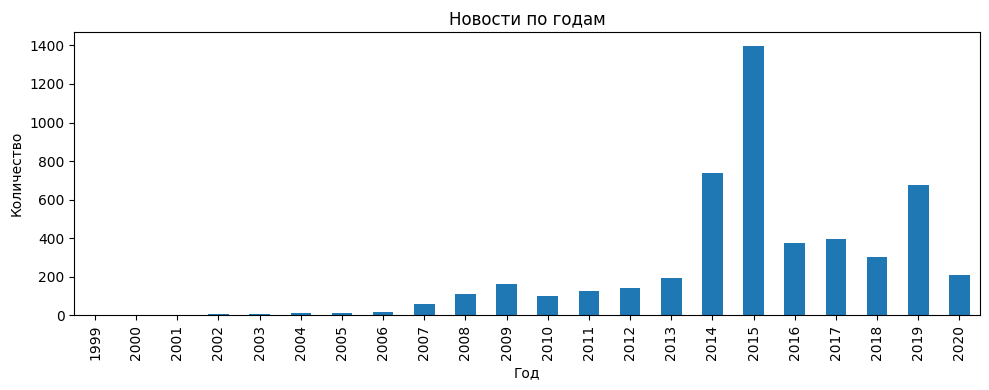

In [9]:
years = df.groupby('published_year').agg(Количество=('alert_flag', 'size'),
                                         Риск=('alert_flag', 'sum')).sort_index()
print('Период:', int(df['published_year'].min()), '–', int(df['published_year'].max()))
display(years)

fig, ax = plt.subplots(figsize=(10, 4))
years['Количество'].plot.bar(ax=ax)
ax.set(xlabel='Год', ylabel='Количество', title='Новости по годам')
plt.tight_layout()
plt.show()

## 9. Длина текстов

Слишком короткие фрагменты содержат мало контекста, а длинные тексты при обучении Transformer могут обрезаться. Посмотрим на длины в словах и символах — это поможет обосновать параметры токенизации.

,Символов в тексте,Слов в тексте,Символов в заголовке
count,5041.0,5041.0,5041.0
mean,553.6,75.1,63.1
std,221.0,29.1,18.1
min,63.0,9.0,0.0
25%,393.0,54.0,51.0
50%,532.0,73.0,63.0
75%,688.0,94.0,75.0
90%,854.0,114.0,86.0
95%,963.0,128.0,90.0
99%,1182.6,149.6,108.0


,count,mean,std,min,25%,50%,75%,max
alert_flag,,,,,,,,
0,4787.0,76.2,28.9,9.0,55.0,74.0,95.0,188.0
1,254.0,54.6,24.1,10.0,37.0,51.5,70.0,171.0


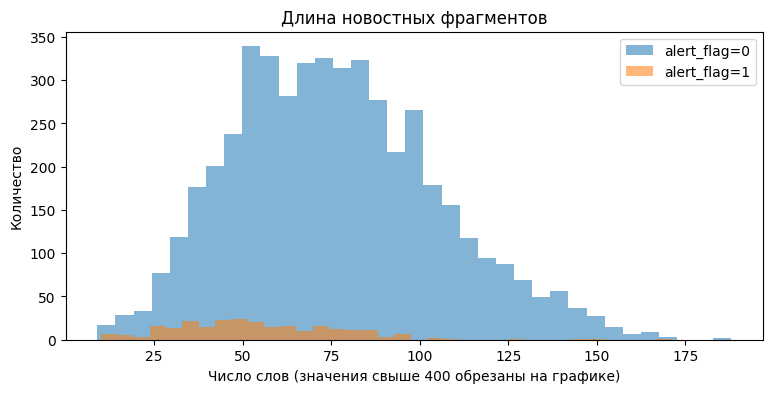

Заголовок уже содержится в тексте: 5040 из 5041


In [10]:
text = df['text_fragment'].fillna('').astype(str)
title = df['title'].fillna('').astype(str)
df_len = pd.DataFrame({
    'Символов в тексте': text.str.len(),
    'Слов в тексте': text.str.split().str.len(),
    'Символов в заголовке': title.str.len(),
    'alert_flag': df['alert_flag']
})
display(df_len.drop(columns='alert_flag').describe(percentiles=[.25, .5, .75, .90, .95, .99]).round(1))
display(df_len.groupby('alert_flag')['Слов в тексте'].describe().round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for label in [0, 1]:
    words = df_len.loc[df_len['alert_flag'] == label, 'Слов в тексте']
    ax.hist(words.clip(upper=400), bins=35, alpha=.55, label=f'alert_flag={label}')
ax.set(xlabel='Число слов (значения свыше 400 обрезаны на графике)',
       ylabel='Количество', title='Длина новостных фрагментов')
ax.legend()
plt.show()

included = [bool(t.strip()) and bool(h.strip()) and h.strip().casefold() in t.casefold()
            for t, h in zip(text, title)]
print('Заголовок уже содержится в тексте:', sum(included), 'из', len(df))

## 10. Проверка разметки

Словарь `found_risk_keywords` нужен для анализа, но **не будет входным признаком модели**. Наличие слова «сбой» или «санкции» ещё не означает, что риск относится к рассматриваемому банку. Аналогично пустой список ключевых слов сам по себе не доказывает отсутствие риска.

In [11]:
has_keywords = df['found_risk_keywords'].fillna('').astype(str).str.strip().ne('')
keyword_check = pd.crosstab(df['alert_flag'], has_keywords)
keyword_check = keyword_check.reindex(index=[0, 1], columns=[False, True], fill_value=0)
keyword_check.index = ['Нет риска', 'Есть риск']
keyword_check.columns = ['Нет ключевых слов', 'Есть ключевые слова']
display(keyword_check)

# Одинаковая группа событий иногда относится к разным банкам и имеет разные метки.
ambiguous_groups = df.groupby('event_group_id')['alert_flag'].nunique()
ambiguous_groups = ambiguous_groups[ambiguous_groups > 1].index
print('Групп событий с разными метками:', len(ambiguous_groups))
display(df[df['event_group_id'].isin(ambiguous_groups)]
        [['event_group_id', 'entity_norm', 'alert_flag', 'title']]
        .sort_values(['event_group_id', 'entity_norm']).head(24))

print('Логических противоречий между бинарной и многоклассовой метками:',
      int(contradictions.sum()))

,Нет ключевых слов,Есть ключевые слова
Нет риска,4305,482
Есть риск,0,254


Групп событий с разными метками: 5


,event_group_id,entity_norm,alert_flag,title
21,eg_nat5_000022,ВТБ,0,"В Днепре радикалы заблокировали отделение ""дочки"" Сбербанка"
29,eg_nat5_000022,Сбербанк,1,"В Днепре радикалы заблокировали отделение ""дочки"" Сбербанка"
139,eg_nat5_000136,ВТБ,0,Число заходов россиян на сайты мошенников увеличилось в 10 раз
778,eg_nat5_000136,Промсвязьбанк,1,Число заходов россиян на сайты мошенников увеличилось в 10 раз
201,eg_nat5_000197,ВТБ,1,Дворкович: власти договариваются с Китаем о финансировании для российских нефтяных компаний
418,eg_nat5_000197,Сбербанк,0,Дворкович: власти договариваются с Китаем о финансировании для российских нефтяных компаний
581,eg_nat5_000221,Альфа-Банк,1,Греф: мошенники вбросили в систему Сбербанка несколько миллионов фальшивых рублей
228,eg_nat5_000221,Промсвязьбанк,0,Греф: мошенники вбросили в систему Сбербанка несколько миллионов фальшивых рублей
815,eg_nat5_000221,Сбербанк,1,Греф: мошенники вбросили в систему Сбербанка несколько миллионов фальшивых рублей
565,eg_nat5_000364,Газпромбанк,0,МИД: Россия не признает законность американских санкций.


Логических противоречий между бинарной и многоклассовой метками: 0


## 11. Дубликаты и утечки между выборками

Повтор одного текста для разных банков не обязательно является ошибкой. Но одинаковые или почти одинаковые публикации **в разных split** могут завышать оценку качества. Проверим группы событий и точные совпадения нормализованного текста.

In [12]:
def normalize_text(value):
    return re.sub(r'\s+', ' ', str(value).lower().replace('ё', 'е')).strip()

normalized = df['text_fragment'].map(normalize_text)
audit = df[['sample_id', 'event_group_id', 'split', 'title', 'entity_norm', 'alert_flag']].copy()
audit['normalized_text'] = normalized

cross_group = int((df.groupby('event_group_id')['split'].nunique() > 1).sum())
cross_text = int((audit.groupby('normalized_text')['split'].nunique() > 1).sum())
cross_title = int((df.assign(normalized_title=title.map(normalize_text))
                   .groupby('normalized_title')['split'].nunique() > 1).sum())

leak_checks = pd.DataFrame({
    'Проверка': [
        'Повторяющиеся sample_id',
        'Полные совпадения text_fragment (строк сверх первой)',
        'Полные совпадения text_fragment + entity_norm',
        'event_group_id в разных split',
        'Одинаковые тексты в разных split',
        'Одинаковые заголовки в разных split'
    ],
    'Количество': [
        int(df['sample_id'].duplicated().sum()),
        int(audit['normalized_text'].duplicated().sum()),
        int(audit.duplicated(['normalized_text', 'entity_norm']).sum()),
        cross_group, cross_text, cross_title
    ]
})
display(leak_checks)

if cross_text:
    text_keys = audit.groupby('normalized_text')['split'].nunique()
    display(audit[audit['normalized_text'].isin(text_keys[text_keys > 1].index)]
            [['sample_id', 'split', 'entity_norm', 'title']].head(15))

assert cross_group == 0, 'Группы событий пересекаются между выборками: проверь датасет.'

,Проверка,Количество
0,Повторяющиеся sample_id,0
1,Полные совпадения text_fragment (строк сверх первой),61
2,Полные совпадения text_fragment + entity_norm,0
3,event_group_id в разных split,0
4,Одинаковые тексты в разных split,0
5,Одинаковые заголовки в разных split,166


## 12. Поиск очень похожих новостей

Проверка по `event_group_id` не гарантирует отсутствия близких по смыслу публикаций. Ниже сравниваем тексты с помощью TF-IDF и косинусного сходства **только между разными выборками**. Полученные пары — кандидаты на ручную проверку, а не автоматически подтверждённые утечки.

Для сохранения скорости используются словные униграммы и биграммы, обработка небольшими пакетами. Порог сходства 0,85 служит для диагностики и не подбирается по качеству модели.

In [13]:
compare_texts = (title.map(normalize_text) + ' ' + normalized).str.strip()
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                             max_features=60_000, dtype=np.float32)
X = vectorizer.fit_transform(compare_texts)

pairs = []
for left_split, right_split in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    left_idx = np.flatnonzero(df['split'].to_numpy() == left_split)
    right_idx = np.flatnonzero(df['split'].to_numpy() == right_split)
    for start in range(0, len(left_idx), 128):
        block_idx = left_idx[start:start + 128]
        scores = (X[block_idx] @ X[right_idx].T).tocoo()
        matches = np.flatnonzero(scores.data >= 0.85)
        for n in matches:
            i = int(block_idx[scores.row[n]])
            j = int(right_idx[scores.col[n]])
            pairs.append({
                'sample_id_1': df.at[i, 'sample_id'], 'split_1': left_split,
                'sample_id_2': df.at[j, 'sample_id'], 'split_2': right_split,
                'similarity': round(float(scores.data[n]), 4),
                'title_1': df.at[i, 'title'], 'title_2': df.at[j, 'title'],
                'alert_flag_1': int(df.at[i, 'alert_flag']),
                'alert_flag_2': int(df.at[j, 'alert_flag'])
            })

near_duplicates = pd.DataFrame(pairs, columns=[
    'sample_id_1', 'split_1', 'sample_id_2', 'split_2', 'similarity',
    'title_1', 'title_2', 'alert_flag_1', 'alert_flag_2'
])
if not near_duplicates.empty:
    near_duplicates = near_duplicates.sort_values('similarity', ascending=False)

print('Пар с TF-IDF similarity ≥ 0.85 между разными split:', len(near_duplicates))
display(near_duplicates.head(15))

Пар с TF-IDF similarity ≥ 0.85 между разными split: 34


,sample_id_1,split_1,sample_id_2,split_2,similarity,title_1,title_2,alert_flag_1,alert_flag_2
3,ml_nat5_final_001917,train,ml_nat5_final_002704,valid,0.9275,Банки возобновляют валютно-обменные операции по рублевым карточкам,Белорусские банки возобновляют валютные интернет-операции,0,0
25,ml_nat5_final_004097,train,ml_nat5_final_004096,test,0.9259,Банки не исключают снижения ставок по потребительским кредитам вслед за Сбербанком,Банки не исключают снижения ставок по потребительским кредитам вслед за Сбербанком,0,0
13,ml_nat5_final_001156,train,ml_nat5_final_000735,test,0.9209,Сбербанк сократит 25 тысяч человек,Сбербанк сократит 25 тысяч человек,0,0
10,ml_nat5_final_000558,train,ml_nat5_final_002582,test,0.9094,"""Райффайзенбанк"" внедрил СХД Violin Memory","""Райффайзенбанк"" внедрил СХД Violin Memory",0,0
23,ml_nat5_final_003714,train,ml_nat5_final_003715,test,0.9084,"""Ведомости"" узнали о сроках IPO Пробизнесбанка","""Ведомости"" узнали о сроках IPO Пробизнесбанка",0,0
5,ml_nat5_final_002388,train,ml_nat5_final_001297,valid,0.8956,Госдума разрешила дать деньги банкам,Народ побежал из Москвы,0,0
20,ml_nat5_final_003179,train,ml_nat5_final_003178,test,0.8893,ЦБ повысит норматив ликвидности по графику,ЦБ повысит норматив ликвидности по графику,0,0
1,ml_nat5_final_000680,train,ml_nat5_final_001250,valid,0.8873,«Локомотив» сообщил о зараженных коронавирусом в клубе,«Локомотив» сообщил о зараженных коронавирусом в клубе,0,0
12,ml_nat5_final_000741,train,ml_nat5_final_000550,test,0.8839,"Банк России опубликовал карту точек банковского обслуживания, где можно сдать биометрию","Банк России опубликовал карту точек банковского обслуживания, где можно сдать биометрию",0,0
26,ml_nat5_final_004111,train,ml_nat5_final_004112,test,0.8818,Рынок долгового капитала в РФ вернулся в 2006 г.,Рынок долгового капитала в РФ вернулся в 2006 г.,0,0


## 13. Выводы EDA и последствия для моделирования

**Особенности данных:** положительный класс составляет около 5% записей, поэтому Accuracy сама по себе малоинформативна; важны F1, Precision и Recall. Для бинарной классификации основной критерий настройки моделей в уже выполненных экспериментах — **F1 положительного класса на validation**. Тестовая выборка предназначена для итоговой оценки.

**Контекст банка:** один фрагмент новости может упоминать несколько организаций; метка относится к конкретному банку. Поэтому в Deep Learning исследовались разные форматы входных данных, включая контекст банка.

**Качество и воспроизводимость:** сохраняем исходные разбиения train/valid/test и не меняем разметку. Близкие публикации между выборками — потенциальный источник оптимистичной оценки метрик; найденные кандидаты требуют отдельной проверки, а не автоматического удаления.

**Признаки и утечки:** `alert_flag` и `risk_type_4cls` — целевые метки; `found_risk_keywords` используется только для диагностического анализа. Его не подаём в качестве входного признака классификатора.

**Следующие части проекта:** `01_baseline_training_reference.ipynb` (классический ML), `02_training_experiments_archive.ipynb` (эксперименты Deep Learning) и `03_binary_experiments_comparison.ipynb` (сопоставление результатов). Многоклассовое исследование по `risk_type_4cls` завершено; его постановка и результаты описаны в `04_multiclass_research_plan.md` и ноутбуках 05–11.


In [14]:
print(f'Всего записей: {len(df)}')
print(f'Положительных примеров: {int(df.alert_flag.sum())} ({df.alert_flag.mean():.2%})')
print(f'Положительных в train: {int(split_table.loc["train", "Есть риск"])}')
print(f'Источников: {df.source.nunique()}, банков: {df.entity_norm.nunique()}')
print(f'Годы: {int(df.published_year.min())}–{int(df.published_year.max())}')
print(f'Групп событий в разных split: {cross_group}')
print(f'Кандидатов в похожие пары между split: {len(near_duplicates)}')

# Производные диагностические таблицы отдельно от исходного CSV.
REPORT_DIR = PROJECT_ROOT / 'results' / 'eda'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
column_summary.to_csv(REPORT_DIR / 'column_summary.csv', index=False)
split_table.to_csv(REPORT_DIR / 'split_summary.csv')
near_duplicates.to_csv(REPORT_DIR / 'near_duplicate_candidates.csv', index=False)
print('Отчёты EDA сохранены:', REPORT_DIR)
print('Следующий ноутбук: 01_baseline_training_reference.ipynb')


Всего записей: 5041
Положительных примеров: 254 (5.04%)
Положительных в train: 176
Источников: 5, банков: 15
Годы: 1999–2020
Групп событий в разных split: 0
Кандидатов в похожие пары между split: 34
Отчёты EDA сохранены: D:\bank_risk_diploma_final_multiclass_2026_10_25\_review_execution\results\eda
Следующий ноутбук: 01_baseline_training_reference.ipynb
